# 1.0 — Setup & Imports

Mounts Google Drive (when running in Colab), imports all required libraries, and fixes global random seeds for reproducibility.

In [1]:
from scipy.io import loadmat
# ── Standard library ──────────────────────────────────────────────────────────
import os
import sys
import io
import gc
import json
import time
import random
import warnings
from pathlib import Path

# ── Google Colab (optional) ───────────────────────────────────────────────────
IN_COLAB = False
IN_COLAB = False
IN_COLAB = False

# ── Third-party ───────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, cohen_kappa_score, f1_score,
    ConfusionMatrixDisplay,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ── Global settings ───────────────────────────────────────────────────────────
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('Python    :', sys.version.split()[0])
print('TensorFlow:', tf.__version__)


Python    : 3.13.16
TensorFlow: 2.21.0


# 2.0 — Configuration

All tunable hyper-parameters, file paths, and architecture constants live here.
Change values in this cell only — nothing else in the notebook should need editing for a standard run.

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IN_KAGGLE = Path('/kaggle').exists() or Path('/kaggle/working').exists()

if IN_KAGGLE:
    PROJECT_ROOT = Path('/kaggle/working')
    MODEL_DIR    = Path('/kaggle/working/models')
    RESULTS_DIR  = Path('/kaggle/working/results')
else:
    PROJECT_ROOT = Path('.')
    MODEL_DIR    = Path('models')
    RESULTS_DIR  = Path('results')

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR    = RESULTS_DIR / 'training_plots'
PLOT_DIR.mkdir(parents=True, exist_ok=True)
VIS_DIR     = RESULTS_DIR / 'scene_visualizations'
VIS_DIR.mkdir(parents=True, exist_ok=True)
VIS_EXCEL_PATH = VIS_DIR / 'initial_classification_maps.xlsx'

# ── Dataset path resolution ──────────────────────────────────────────────────
DATASET_NAME = "Planet Hisar"

data_candidates = (
    list(Path("/kaggle/kin").glob("**/planet.csv"))
    or list(Path("/kaggle/kin").glob("**/k001.csv"))
    or list(Path("/kaggle/working/data").glob("**/planet.csv"))
    or list(Path("/kaggle/working/data").glob("**/k001.csv"))
    or list(Path("/kaggle/working").glob("**/planet.csv"))
    or list(Path("/kaggle/working").glob("**/k001.csv"))
    or list(Path("data").glob("**/planet.csv"))
    or list(Path("examples/planet_data_hisar_uncertainty_quantification/data").glob("**/planet.csv"))
    or list(Path("../data").glob("**/planet.csv"))
    or list(Path("Classification_Uncertainty_Quantification_Analysis/examples/planet_data_hisar_uncertainty_quantification/data").glob("**/planet.csv"))
    or list(Path("/Users/danesh/Desktop/Reports_dias/Classification_Uncertainty_Quantification_Analysis/examples/planet_data_hisar_uncertainty_quantification/data").glob("**/planet.csv"))
)
if data_candidates:
    DATA_FILE = data_candidates[0]
    DATA_DIR = DATA_FILE.parent
    lbl_cands = (
        [DATA_DIR / "planetgt.csv", DATA_DIR / "k002.csv"]
        + list(Path("/kaggle/kin").glob("**/planetgt.csv"))
        + list(Path("/kaggle/kin").glob("**/k002.csv"))
        + list(Path("/kaggle/working/data").glob("**/planetgt.csv"))
        + list(Path("/kaggle/working/data").glob("**/k002.csv"))
        + [Path("data/planetgt.csv"), Path("../data/planetgt.csv"), Path("examples/planet_data_hisar_uncertainty_quantification/data/planetgt.csv")]
    )
    LABEL_FILE = next((p for p in lbl_cands if p.exists()), DATA_DIR / "planetgt.csv")
else:
    DATA_DIR = Path("/kaggle/kin/planethisar-dataset-k09") if Path("/kaggle").exists() else Path("data")
    DATA_FILE = DATA_DIR / "planet.csv"
    LABEL_FILE = DATA_DIR / "planetgt.csv"


PERCENTILE_CLIP = (2.0, 98.0)
PATCH_SIZE  = 9
INNER_PATCH = 3

print("Data file:    ", DATA_FILE)
print("Label file:   ", LABEL_FILE)
print("Model dir:    ", MODEL_DIR)
print("Results dir:  ", RESULTS_DIR)

# ── Visualisation palette ─────────────────────────────────────────────
import colorsys
from matplotlib.colors import ListedColormap

CLASS_COLOR_BASE = [
    '#0000FF', '#00FF00', '#FF0000', '#00FFFF', '#FF00FF',
    '#FFFF00', '#A52A2A', '#FFA500', '#7FFF00', '#8A2BE2',
]
BACKGROUND_COLOR = '#000000'
UNCERTAIN_COLOR  = '#808080'

def _generate_extra_shades(n_extra, hue_offset=0.05, sat=0.85, val=0.95):
    """Bold, highly-saturated extra hues in the same style as CLASS_COLOR_BASE."""
    shades = []
    for i in range(n_extra):
        hue = (hue_offset + i / max(n_extra, 1)) % 1.0
        r, g, b = colorsys.hsv_to_rgb(hue, sat, val)
        shades.append('#%02x%02x%02x' % (int(r * 255), int(g * 255), int(b * 255)))
    return shades

def get_class_colors(n):
    """Return n visually distinct hex colours; extends past the base 10 with
    additional bold shades generated in the same saturated style."""
    if n <= len(CLASS_COLOR_BASE):
        return CLASS_COLOR_BASE[:n]
    return CLASS_COLOR_BASE + _generate_extra_shades(n - len(CLASS_COLOR_BASE))

def resolve_uncertain_color(class_colors, preferred=UNCERTAIN_COLOR, min_dist=60):
    """Return `preferred` unless it visually clashes with any class colour, in
    which case fall back to a distinct dark slate so 'Uncertain' never collides."""
    def _hex_to_rgb(h):
        h = h.lstrip('#')
        return tuple(int(h[i:i+2], 16) for i in (0, 2, 4))
    pr, pg, pb = _hex_to_rgb(preferred)
    for c in class_colors:
        cr, cg, cb = _hex_to_rgb(c)
        dist = ((pr - cr) ** 2 + (pg - cg) ** 2 + (pb - cb) ** 2) ** 0.5
        if dist < min_dist:
            return '#2F2F2F'
    return preferred

def get_display_cmap(num_classes):
    """Build a ListedColormap: index 0 = background black, 1..K = class colours."""
    return ListedColormap([BACKGROUND_COLOR] + get_class_colors(num_classes))

def get_scene_rgb(x_img, bands):
    """Select three bands as an approximate RGB composite; clip to [0, 1].
    For 4-band imagery (B, G, R, NIR), bands [2, 1, 0] form natural RGB."""
    if bands == 4:
        rgb_idx = [2, 1, 0]
    elif bands >= 6:
        rgb_idx = [bands // 2 - 1, bands // 2, bands // 2 + 1]
    elif bands >= 3:
        rgb_idx = [0, 1, 2]
    else:
        raise ValueError(f"Need at least 3 bands to form RGB, got {bands}.")
    return np.clip(x_img[:, :, rgb_idx], 0.0, 1.0)

# ── Restored DAPM Training Config (auto-restored) ──
DAPM_DIR = MODEL_DIR
DAPM_DIR.mkdir(parents=True, exist_ok=True)

def _resolve_dapm_backbone(model_key):
    cands = [
        MODEL_DIR / f'{model_key}_best.keras',
        Path(f'/kaggle/working/models/{model_key}_best.keras'),
        Path(f'models/{model_key}_best.keras'),
    ]
    for c in cands:
        if c.exists():
            return c
    for p in sorted(Path('/kaggle/kin').glob(f'**/{model_key}_best.keras')):
        return p
    return cands[0]

MODEL_KEYS = ['AlexNet_CNN', 'GFNet', 'ViT_UNet']
MODEL_FILES = {k: _resolve_dapm_backbone(k) for k in MODEL_KEYS}

FREEZE_BACKBONE = True
MAX_TARGET_UNLABELED = 2000
TARGET_VAL_FRACTION = 0.10

LATENT_DIM = 64
DECODER_HIDDEN_DIM = 256
DISCRIM_HIDDEN_DIM = 128
CLASSIFIER_HIDDEN_DIM = 128
DIFFUSION_HIDDEN_DIM = 256
T_EMBED_DIM = 32

STAGE1_EPOCHS = 3
STAGE2_EPOCHS = 3
BATCH_SIZE = 256
STAGE1_LR = 1e-3
STAGE2_LR = 1e-3

LAMBDA_SRC_RECON = 1.0
LAMBDA_TGT_RECON = 1.0
LAMBDA_KL = 0.01
LAMBDA_CE = 1.0
LAMBDA_DOMAIN = 0.2
LAMBDA_TGT_DIFF = 0.5

DIFFUSION_T = 100
BETA_START = 1e-4
BETA_END = 2e-2


Data file:     /kaggle/kin/datasets/daneshjangra/planethisar-dataset-k09/planet.csv
Label file:    /kaggle/kin/datasets/daneshjangra/planethisar-dataset-k09/planetgt.csv
Model dir:     /kaggle/working/models
Results dir:   /kaggle/working/results


# 3.0 — Data Pipeline

## 3.1 — Loading & Normalisation

Reads the multispectral CSV files and applies per-band min-max normalisation.

In [3]:
def load_scene_from_mat(data_path, label_path, data_key=None, label_key=None):
    """Load Planet Hisar scene + reference labels from headerless CSV files (planet.csv, planetgt.csv) reshaped to (1733, 2647, 4) C-order.

    CRITICAL: Both planet.csv and planetgt.csv have NO header row (header=None).
    Data shape: (1733, 2647, 4), float32.
    Label shape: (1733, 2647), int32 (values 0..8, 0 = background).
    Each band is robustly normalised using percentile clipping [2.0, 98.0].
    """
    x = pd.read_csv(str(data_path), header=None, dtype=np.float32).to_numpy(dtype=np.float32).reshape((1733, 2647, 4), order="C")
    y = pd.read_csv(str(label_path), header=None, dtype=np.float32).to_numpy(dtype=np.float32).astype(np.int32).reshape((1733, 2647), order="C")

    height, width, bands = x.shape

    # Robust per-band percentile stretch [2.0, 98.0]
    for b in range(bands):
        band = x[:, :, b]
        lo = np.percentile(band, PERCENTILE_CLIP[0])
        hi = np.percentile(band, PERCENTILE_CLIP[1])
        denom = max(hi - lo, 1e-8)
        x[:, :, b] = (np.clip(band, lo, hi) - lo) / denom

    return x, y, height, width, bands


def extract_labeled_patches(x, y, patch_size=9):
    """Extract (patch_size x patch_size) spatial patches around every labelled pixel (y > 0)."""
    pad   = patch_size // 2
    x_pad = np.pad(x, ((pad, pad), (pad, pad), (0, 0)), mode="edge")

    coords  = np.argwhere(y > 0)
    patches = np.empty((coords.shape[0], patch_size, patch_size, x.shape[-1]), dtype=np.float32)
    labels  = np.empty((coords.shape[0],), dtype=np.int32)

    for i, (r, c) in enumerate(coords):
        patches[i] = x_pad[r:r + patch_size, c:c + patch_size, :]
        labels[i]  = int(y[r, c]) - 1  # 1-indexed to 0..K-1

    return patches, labels, coords

def extract_labeled_patches_with_coords(x_img, y_img, patch_size=9):
    return extract_labeled_patches(x_img, y_img, patch_size)


## 3.2 — Patch Extraction

Extracts fixed-size spatial patches centred on given pixel coordinates.
Separate helpers handle labeled (source) and unlabeled (target) pixels.

In [4]:
def extract_patches_from_coords(x_img, coords, patch_size=9):
    """Extract (patch_size x patch_size x bands) patches at each (row, col) coordinate."""
    pad   = patch_size // 2
    x_pad = np.pad(x_img, ((pad, pad), (pad, pad), (0, 0)), mode='edge')
    out   = np.empty((coords.shape[0], patch_size, patch_size, x_img.shape[-1]), dtype=np.float32)
    for i, (r, c) in enumerate(coords):
        out[i] = x_pad[r:r + patch_size, c:c + patch_size, :]
    return out


def extract_labeled_patches_with_coords(x_img, y_img, patch_size=9):
    """Return patches, 0-based labels, and coordinates for all labeled (y > 0) pixels."""
    coords   = np.argwhere(y_img > 0)
    x_patches = extract_patches_from_coords(x_img, coords, patch_size=patch_size)
    y_labels  = np.array([int(y_img[r, c]) - 1 for r, c in coords], dtype=np.int32)
    return x_patches, y_labels, coords


def extract_unlabeled_patches_with_coords(x_img, y_img, patch_size=9, max_samples=None, seed=42):
    """Return patches and coordinates for unlabeled (y == 0) pixels, with optional subsampling."""
    coords = np.argwhere(y_img == 0)
    if max_samples is not None and coords.shape[0] > max_samples:
        rng    = np.random.default_rng(seed)
        keep   = rng.choice(coords.shape[0], size=max_samples, replace=False)
        coords = coords[keep]
    x_patches = extract_patches_from_coords(x_img, coords, patch_size=patch_size)
    return x_patches, coords


## 3.3 — Build Train / Val / Test Splits

Loads the image, extracts source (labeled) and target (unlabeled) patches,
and performs stratified splits.

In [5]:
# [auto-fix: hoisted definition so it exists before first use]  <MAX_TARGET_UNLABELED>
MAX_TARGET_UNLABELED = 2000

TRAIN_PERCENT        = 0.75
VAL_SPLIT_FROM_TRAIN = 0.20
TARGET_VAL_FRACTION  = 0.10


In [6]:
x_img, y_img, H, W, B = load_scene_from_mat(DATA_FILE, LABEL_FILE)
X_all, y_all, coords_all = extract_labeled_patches_with_coords(x_img, y_img, PATCH_SIZE)
num_classes = int(np.unique(y_all).size)

# Source domain: stratified 75 / 25 train+val / test split
# FIX C1/C3/C4 — shared train / val / cal / eval split (identical code in every notebook) ──
# SPLIT_MODE = "spatial_block": whole spatial blocks go to one role and training
#   pixels whose 9x9 patch would contain a cal/eval pixel are dropped, so no
#   labelled test pixel is ever seen inside a training patch.
# SPLIT_MODE = "random": legacy stratified pixel-wise split (spatially leaky).
import numpy as _np_split
SPLIT_MODE        = globals().get("SPLIT_MODE", "spatial_block")
SPLIT_SEED        = 42
SPLIT_BLOCK       = 10
SPLIT_TRAIN_FRAC  = 0.75   # fraction of labelled pixels assigned to train+val
SPLIT_VAL_FRAC    = 0.20   # fraction of train+val used for validation / checkpointing
SPLIT_CAL_FRAC    = 0.50   # fraction of the held-out pool used for conformal calibration


def make_shared_split(y_img, patch_size=9, mode=None, seed=SPLIT_SEED,
                      train_frac=SPLIT_TRAIN_FRAC, val_frac=SPLIT_VAL_FRAC,
                      cal_frac=SPLIT_CAL_FRAC, block=SPLIT_BLOCK):
    """Return dict of index arrays (into np.argwhere(y_img > 0) order):
    train, val, cal, eval, test (= cal U eval)."""
    mode   = mode or SPLIT_MODE
    coords = _np_split.argwhere(y_img > 0)
    labels = y_img[y_img > 0].astype(int) - 1
    n, K   = len(labels), int(labels.max()) + 1
    rng    = _np_split.random.default_rng(seed)
    roles  = _np_split.full(n, -1)                       # 0 train, 1 val, 2 cal, 3 eval
    held   = 1.0 - train_frac
    frac   = _np_split.array([train_frac * (1 - val_frac), train_frac * val_frac,
                              held * cal_frac, held * (1 - cal_frac)])
    if mode == "random":
        from sklearn.model_selection import train_test_split as _tts
        idx = _np_split.arange(n)
        def _strat(a):
            cnt = _np_split.bincount(labels[a], minlength=K)
            return labels[a] if cnt[cnt > 0].min() >= 2 else None
        tv, te = _tts(idx, train_size=train_frac, random_state=seed, stratify=_strat(idx))
        tr, va = _tts(tv, test_size=val_frac, random_state=seed, stratify=_strat(tv))
        ca, ev = _tts(te, test_size=1 - cal_frac, random_state=seed, stratify=_strat(te))
        for r, a in enumerate([tr, va, ca, ev]):
            roles[a] = r
    else:
        bid = (coords[:, 0] // block) * 100000 + (coords[:, 1] // block)
        ub, inv = _np_split.unique(bid, return_inverse=True)
        cnt = _np_split.zeros((len(ub), K))
        _np_split.add.at(cnt, (inv, labels), 1)
        target = frac[None, :] * cnt.sum(0)[:, None]          # (K, 4)
        have   = _np_split.zeros((K, 4))
        order  = rng.permutation(len(ub))
        # rare classes first so each role receives some of them
        rarity = (cnt / _np_split.maximum(cnt.sum(0, keepdims=True), 1)).max(1)
        order  = order[_np_split.argsort(-rarity[order], kind="stable")]
        for b in order:
            w    = cnt[b]
            need = ((target - have) / _np_split.maximum(target, 1)) * w[:, None]
            role = int(_np_split.argmax(need.sum(0)))
            have[:, role] += w
            roles[inv == b] = role
        # drop training/validation pixels whose patch would contain a held-out pixel
        pad  = patch_size // 2
        grid = _np_split.zeros(y_img.shape, dtype=bool)
        hc   = coords[roles >= 2]
        grid[hc[:, 0], hc[:, 1]] = True
        from scipy.ndimage import maximum_filter as _mf
        near = _mf(grid.astype(_np_split.uint8), size=2 * pad + 1) > 0
        drop = (roles <= 1) & near[coords[:, 0], coords[:, 1]]
        roles[drop] = -1
    out = {k: _np_split.where(roles == r)[0] for r, k in enumerate(["train", "val", "cal", "eval"])}
    out["test"] = _np_split.sort(_np_split.concatenate([out["cal"], out["eval"]]))
    out["coords"], out["labels"], out["mode"] = coords, labels, mode
    return out


def check_split_alignment(split, ns):
    """Fail loudly if the notebook's labelled-patch order differs from the shared split order
    (row-major over y > 0). Any 1-D label vector of the same length is compared up to relabelling."""
    lab = split["labels"]; n = len(lab); checked = []
    for name in ("y", "Y", "y_all", "y_labels", "y_labeled"):
        v = ns.get(name)
        if isinstance(v, _np_split.ndarray) and v.ndim == 1 and len(v) == n:
            pairs = set(zip(lab.tolist(), _np_split.asarray(v).astype(int).tolist()))
            if len(pairs) != len(set(lab.tolist())) or len({b for _, b in pairs}) != len(pairs):
                raise RuntimeError(f"shared split is not aligned with label vector '{name}'")
            checked.append(name)
    print("split alignment verified against:", checked or "nothing (no 1-D label vector in scope)")


def describe_split(split, num_classes):
    import pandas as _pd
    rows = {k: _np_split.bincount(split["labels"][split[k]], minlength=num_classes)
            for k in ["train", "val", "cal", "eval"]}
    df = _pd.DataFrame(rows); df.index.name = "class"
    print(f"Split mode: {split['mode']}  |  sizes:", {k: int(v.sum()) for k, v in rows.items()})
    return df


# FIX C1/C4: shared split (identical in every notebook)
SPLIT = make_shared_split(y_img, patch_size=PATCH_SIZE)
check_split_alignment(SPLIT, globals())
display(describe_split(SPLIT, num_classes))
x_train, y_train, coords_train = X_all[SPLIT["train"]], y_all[SPLIT["train"]], coords_all[SPLIT["train"]]
x_val,   y_val,   coords_val   = X_all[SPLIT["val"]],   y_all[SPLIT["val"]],   coords_all[SPLIT["val"]]
x_test,  y_test,  coords_test  = X_all[SPLIT["test"]],  y_all[SPLIT["test"]],  coords_all[SPLIT["test"]]

# Target domain: unlabeled pixels, randomly sub-sampled
X_target_all, coords_target_all = extract_unlabeled_patches_with_coords(
    x_img, y_img, patch_size=PATCH_SIZE,
    max_samples=MAX_TARGET_UNLABELED, seed=SEED,
)
x_target_train, x_target_val, coords_target_train, coords_target_val = train_test_split(
    X_target_all, coords_target_all,
    test_size=TARGET_VAL_FRACTION, random_state=SEED, shuffle=True,
)

print('x_img           :', x_img.shape, '  y_img:', y_img.shape)
print('Source train/val/test:', x_train.shape, x_val.shape, x_test.shape)
print('Target train/val    :', x_target_train.shape, x_target_val.shape)
print('num_classes         :', num_classes)


split alignment verified against: ['y_all']
Split mode: spatial_block  |  sizes: {'train': 176021, 'val': 42833, 'cal': 62188, 'eval': 62188}


,train,val,cal,eval
class,,,,
0,4620,1119,1560,1559
1,15326,3845,5465,5465
2,31622,7800,11250,11250
3,2257,507,897,901
4,29675,7031,10064,10064
5,9867,2289,3560,3556
6,15307,3874,5658,5659
7,67347,16368,23734,23734


x_img           : (1733, 2647, 4)   y_img: (1733, 2647)
Source train/val/test: (176021, 9, 9, 4) (42833, 9, 9, 4) (124376, 9, 9, 4)
Target train/val    : (1800, 9, 9, 4) (200, 9, 9, 4)
num_classes         : 8


# 4.0 — Custom Keras Layers & Backbone Loaders

## 4.1 — Custom Layers for Base Models

Registers the serialisable custom layers required to reload the pre-trained `.keras` files.
These layers are **not** trained here — they are part of the frozen backbones.

In [7]:
try:
    keras.config.enable_unsafe_deserialization()
except Exception:
    pass

@tf.keras.utils.register_keras_serializable()
class PatchExtractor(layers.Layer):
    """Extract non-overlapping image patches via tf.image.extract_patches."""

    def __init__(self, patch_size=3, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, images):
        patches   = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding='VALID',
        )
        batch     = tf.shape(images)[0]
        num_patches = tf.shape(patches)[1] * tf.shape(patches)[2]
        patch_dim = tf.shape(patches)[-1]
        return tf.reshape(patches, [batch, num_patches, patch_dim])

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'patch_size': self.patch_size})
        return cfg


@tf.keras.utils.register_keras_serializable()
class PatchPositionEncoder(layers.Layer):
    """Project patches and add learned positional embeddings."""

    def __init__(self, num_patches, projection_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patches    = num_patches
        self.projection_dim = projection_dim
        self.projection          = layers.Dense(projection_dim)
        self.position_embedding  = layers.Embedding(input_dim=num_patches, output_dim=projection_dim)

    def call(self, patches):
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        return self.projection(patches) + self.position_embedding(positions)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'num_patches': self.num_patches, 'projection_dim': self.projection_dim})
        return cfg


@tf.keras.utils.register_keras_serializable()
class GlobalFilterLayer(layers.Layer):
    """GFNet global filter: learnable 2-D frequency-domain weights."""

    def __init__(self, token_side, **kwargs):
        super().__init__(**kwargs)
        self.token_side = token_side

    def build(self, input_shape):
        channels = int(input_shape[-1])
        self.w_real = self.add_weight(
            name='w_real', shape=(self.token_side, self.token_side, channels),
            initializer='glorot_uniform', trainable=True,
        )
        self.w_imag = self.add_weight(
            name='w_imag', shape=(self.token_side, self.token_side, channels),
            initializer='zeros', trainable=True,
        )
        super().build(input_shape)

    def call(self, x):
        batch    = tf.shape(x)[0]
        channels = tf.shape(x)[-1]
        x_2d     = tf.reshape(x, [batch, self.token_side, self.token_side, channels])
        # FIX C5: fft2d transforms the two innermost axes, so move channels first and
        # filter over the (token_row, token_col) spatial grid as GFNet intends.
        x_2d       = tf.transpose(x_2d, [0, 3, 1, 2])                       # (B, C, s, s)
        x_fft      = tf.signal.fft2d(tf.cast(x_2d, tf.complex64))
        w_complex  = tf.transpose(tf.complex(self.w_real, self.w_imag), [2, 0, 1])
        x_filtered = x_fft * w_complex
        x_spatial  = tf.math.real(tf.signal.ifft2d(x_filtered))
        x_spatial  = tf.transpose(x_spatial, [0, 2, 3, 1])                  # (B, s, s, C)
        return tf.reshape(x_spatial, [batch, self.token_side * self.token_side, channels])

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'token_side': self.token_side})
        return cfg


@tf.keras.utils.register_keras_serializable()
class PatchEncoderWithCLS(layers.Layer):
    """ViT-style patch encoder with a prepended learnable [CLS] token."""

    def __init__(self, num_patches, projection_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patches    = num_patches
        self.projection_dim = projection_dim
        self.projection         = layers.Dense(projection_dim)
        self.position_embedding = layers.Embedding(input_dim=num_patches + 1, output_dim=projection_dim)

    def build(self, input_shape):
        self.cls_token = self.add_weight(
            name='cls_token', shape=(1, 1, self.projection_dim),
            initializer='zeros', trainable=True,
        )
        super().build(input_shape)

    def call(self, patches):
        batch      = tf.shape(patches)[0]
        patch_proj = self.projection(patches)
        cls_tokens = tf.repeat(self.cls_token, repeats=batch, axis=0)
        x          = tf.concat([cls_tokens, patch_proj], axis=1)
        positions  = tf.range(start=0, limit=self.num_patches + 1, delta=1)
        return x + self.position_embedding(positions)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'num_patches': self.num_patches, 'projection_dim': self.projection_dim})
        return cfg


CUSTOM_OBJECTS = {
    'PatchExtractor'      : PatchExtractor,
    'PatchPositionEncoder': PatchPositionEncoder,
    'GlobalFilterLayer'   : GlobalFilterLayer,
    'PatchEncoderWithCLS' : PatchEncoderWithCLS,
}

# ── Robust Backbone Loader across Python versions (bypasses Lambda bytecode deserialization) ──
import zipfile

def transformer_block(x, num_heads, projection_dim, mlp_dim, dropout_rate, name_prefix):
    """Standard pre-LN transformer block with multi-head attention and a GELU MLP."""
    y = layers.LayerNormalization(epsilon=1e-6, name=f"{name_prefix}_ln1")(x)
    y = layers.MultiHeadAttention(
        num_heads=num_heads, key_dim=projection_dim,
        dropout=dropout_rate, name=f"{name_prefix}_mha",
    )(y, y)
    x = layers.Add(name=f"{name_prefix}_add1")([y, x])

    y = layers.LayerNormalization(epsilon=1e-6, name=f"{name_prefix}_ln2")(x)
    y = layers.Dense(mlp_dim, activation=tf.keras.activations.gelu, name=f"{name_prefix}_mlp1")(y)
    y = layers.Dropout(dropout_rate, name=f"{name_prefix}_drop1")(y)
    y = layers.Dense(projection_dim, activation=tf.keras.activations.gelu, name=f"{name_prefix}_mlp2")(y)
    y = layers.Dropout(dropout_rate, name=f"{name_prefix}_drop2")(y)
    return layers.Add(name=f"{name_prefix}_add2")([y, x])


def build_vit_unet_singlehead(
    input_shape=(9, 9, 4), num_classes=8, inner_patch=3,
    projection_dim=256, num_heads=4, transformer_layers=12,
    mlp_multiplier=2, dropout_rate=0.25, head_units=(512, 256, 128, 64),
):
    """Build a ViT single-head classifier matching dias-baseline-k03."""
    num_patches = (input_shape[0] // inner_patch) * (input_shape[1] // inner_patch)

    inputs = keras.Input(shape=input_shape)
    x      = PatchExtractor(inner_patch, name="vit_patch_extractor")(inputs)
    x      = PatchEncoderWithCLS(num_patches, projection_dim, name="vit_patch_encoder")(x)

    block_list = []
    for i in range(transformer_layers):
        x = transformer_block(
            x, num_heads=num_heads, projection_dim=projection_dim,
            mlp_dim=projection_dim * mlp_multiplier,
            dropout_rate=0.1, name_prefix=f"vit_block_{i+1}",
        )
        if i <= transformer_layers // 2:
            block_list.append(x)
        else:
            x = layers.Add(name=f"vit_skip_add_{i+1}")([x, block_list[transformer_layers - i - 1]])

    x         = layers.Dropout(dropout_rate, name="TRAIN_DROPOUT_1")(x)
    x         = layers.LayerNormalization(epsilon=1e-6, name="vit_cls_norm")(x)
    cls_token = layers.Lambda(lambda t: t[:, 0, :], name="vit_cls_token")(x)

    y = layers.Dense(head_units[0], activation=tf.keras.activations.gelu, name="vit_head_1")(cls_token)
    y = layers.Dropout(dropout_rate, name="TRAIN_DROPOUT_3")(y)
    y = layers.Dense(head_units[1], activation=tf.keras.activations.gelu, name="vit_head_2")(y)
    y = layers.Dense(head_units[2], activation=tf.keras.activations.gelu, name="vit_head_3")(y)
    y = layers.Dropout(dropout_rate, name="TRAIN_DROPOUT_5")(y)
    y = layers.Dense(head_units[3], activation=tf.keras.activations.gelu, name="vit_head_4")(y)
    y = layers.Dropout(dropout_rate, name="TRAIN_DROPOUT_6")(y)

    outputs = layers.Dense(num_classes, activation="softmax", name="vit_logits")(y)
    return keras.Model(inputs, outputs, name="ViT_UNet_SingleHead")


def load_backbone_model(path, model_key, custom_objects, input_shape=(9, 9, 4), num_classes=8):
    """Load model safely without Python bytecode deserialization crash."""
    path_obj = Path(path)
    if not path_obj.exists():
        raise FileNotFoundError(f"Missing base model: {path}")

    if model_key == "ViT_UNet":
        model = build_vit_unet_singlehead(input_shape=input_shape, num_classes=num_classes)
        try:
            model.load_weights(str(path_obj))
        except Exception:
            if zipfile.is_zipfile(path_obj):
                with zipfile.ZipFile(path_obj, "r") as z:
                    if "model.weights.h5" in z.namelist():
                        tmp_w = f"/tmp/{model_key}_weights.h5"
                        with open(tmp_w, "wb") as f_out:
                            f_out.write(z.read("model.weights.h5"))
                        model.load_weights(tmp_w)
                    else:
                        raise
            else:
                raise
        return model
    else:
        return keras.models.load_model(str(path_obj), custom_objects=custom_objects, compile=False, safe_mode=False)


## 4.2 — Load Backbones & Build Feature Extractors

Loads each pre-trained `.keras` model, slices off the final classification head,
and optionally freezes all backbone weights.

In [8]:
def get_feature_extractor(base_model, freeze_backbone=True):
    """Return a sub-model that outputs the penultimate (pre-logit) layer activations."""
    penultimate = base_model.layers[-2].output
    feat_model  = keras.Model(
        base_model.input, penultimate,
        name=f'{base_model.name}_feature_extractor',
    )
    feat_model.trainable = not freeze_backbone
    return feat_model


base_models        = {}
feature_extractors = {}
feature_dims       = {}

for model_key in MODEL_KEYS:
    path = MODEL_FILES[model_key]
    model = load_backbone_model(
        path, model_key, CUSTOM_OBJECTS,
        input_shape=(PATCH_SIZE, PATCH_SIZE, B),
        num_classes=num_classes,
    )
    extractor = get_feature_extractor(model, freeze_backbone=FREEZE_BACKBONE)
    feature_dim = int(extractor.output_shape[-1])

    base_models[model_key]        = model
    feature_extractors[model_key] = extractor
    feature_dims[model_key]       = feature_dim

    print(model_key, 'loaded from', path)
    print('  feature_dim =', feature_dim)


AlexNet_CNN loaded from /kaggle/working/models/AlexNet_CNN_best.keras
  feature_dim = 32


GFNet loaded from /kaggle/working/models/GFNet_best.keras
  feature_dim = 512


ViT_UNet loaded from /kaggle/working/models/ViT_UNet_best.keras
  feature_dim = 64


# 5.0 — DAPM Module Definitions

## 5.1 — Core Keras Layers (Sampling, GRL)

Defines the two custom layers used inside the DAPM heads:
the VAE reparameterisation sampler and the Gradient Reversal Layer (GRL).

In [9]:
@tf.keras.utils.register_keras_serializable()
class Sampling(layers.Layer):
    """VAE reparameterisation trick: z = mu + exp(0.5 * logvar) * eps."""

    def call(self, inputs):
        z_mu, z_logvar = inputs
        eps = tf.random.normal(shape=tf.shape(z_mu))
        return z_mu + tf.exp(0.5 * z_logvar) * eps


@tf.keras.utils.register_keras_serializable()
class GradientReversal(layers.Layer):
    """Flip gradients by -lambda_ during back-propagation (domain adversarial training)."""

    def __init__(self, lambda_=1.0, **kwargs):
        super().__init__(**kwargs)
        self.lambda_ = float(lambda_)

    def call(self, x):
        lambda_ = self.lambda_

        @tf.custom_gradient
        def _flip_gradients(v):
            def grad(dy):
                return -lambda_ * dy
            return v, grad

        return _flip_gradients(x)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'lambda_': self.lambda_})
        return cfg


## 5.2 — DAPM Network Builders

Factory functions for the five sub-networks: encoder (VAE), source/target decoders,
classifier, domain discriminator, and the conditional diffusion model.

In [10]:
def build_dapm_encoder(feature_dim, latent_dim=64, hidden_dim=256):
    """VAE encoder: feature vector → (z_mu, z_logvar, z_sample)."""
    inp      = keras.Input(shape=(feature_dim,), name='enc_feature_in')
    h        = layers.Dense(hidden_dim, activation='relu', name='enc_h1')(inp)
    h        = layers.Dense(hidden_dim, activation='relu', name='enc_h2')(h)
    z_mu     = layers.Dense(latent_dim, name='z_mu')(h)
    z_logvar = layers.Dense(latent_dim, name='z_logvar')(h)
    z        = Sampling(name='z_sample')([z_mu, z_logvar])
    return keras.Model(inp, [z_mu, z_logvar, z], name='dapm_full_encoder')


def build_dapm_decoder(latent_dim, feature_dim, hidden_dim=256, name='dapm_full_decoder'):
    """Decoder: latent vector → reconstructed feature vector."""
    inp = keras.Input(shape=(latent_dim,), name=f'{name}_z_in')
    h   = layers.Dense(hidden_dim, activation='relu', name=f'{name}_h1')(inp)
    h   = layers.Dense(hidden_dim, activation='relu', name=f'{name}_h2')(h)
    out = layers.Dense(feature_dim, activation='linear', name=f'{name}_out')(h)
    return keras.Model(inp, out, name=name)


def build_dapm_classifier(latent_dim, num_classes, hidden_dim=128):
    """Classifier head: latent vector → class probabilities."""
    inp = keras.Input(shape=(latent_dim,), name='clf_z_in')
    h   = layers.Dense(hidden_dim, activation='relu', name='clf_h1')(inp)
    out = layers.Dense(num_classes, activation='softmax', name='clf_out')(h)
    return keras.Model(inp, out, name='dapm_full_classifier')


def build_dapm_discriminator(latent_dim, hidden_dim=128, grl_lambda=1.0):
    """Domain discriminator with Gradient Reversal Layer: latent → P(target domain)."""
    inp = keras.Input(shape=(latent_dim,), name='disc_z_in')
    x   = GradientReversal(lambda_=grl_lambda, name='disc_grl')(inp)
    x   = layers.Dense(hidden_dim, activation='relu', name='disc_h1')(x)
    x   = layers.Dense(hidden_dim, activation='relu', name='disc_h2')(x)
    out = layers.Dense(1, activation='sigmoid', name='disc_out')(x)
    return keras.Model(inp, out, name='dapm_full_discriminator')


def build_dapm_diffusion(latent_dim, num_classes, T=100, t_embed_dim=32, hidden_dim=256):
    """Conditional diffusion noise predictor: (z, y_t, guidance, t) → eps_pred."""
    z_in   = keras.Input(shape=(latent_dim,),   name='diff_z_in')
    y_t_in = keras.Input(shape=(num_classes,),  name='diff_y_t')
    f_in   = keras.Input(shape=(num_classes,),  name='diff_guidance')
    t_in   = keras.Input(shape=(1,), dtype='int32', name='diff_t')

    t_emb    = layers.Embedding(input_dim=T + 1, output_dim=t_embed_dim, name='diff_t_embed')(t_in)
    t_emb    = layers.Flatten(name='diff_t_flat')(t_emb)
    x        = layers.Concatenate(name='diff_concat')([z_in, y_t_in, f_in, t_emb])
    x        = layers.Dense(hidden_dim, activation='relu', name='diff_h1')(x)
    x        = layers.Dense(hidden_dim, activation='relu', name='diff_h2')(x)
    eps_pred = layers.Dense(num_classes, activation='linear', name='diff_eps_pred')(x)

    return keras.Model([z_in, y_t_in, f_in, t_in], eps_pred, name='dapm_full_diffusion')


# 6.0 — Training Utilities

## 6.1 — Loss Functions

Shared loss helpers used by both training stages.

In [11]:
def kl_loss_from_stats(z_mu, z_logvar):
    """KL divergence from N(0,1): averaged over batch."""
    return -0.5 * tf.reduce_mean(
        tf.reduce_sum(1.0 + z_logvar - tf.square(z_mu) - tf.exp(z_logvar), axis=-1)
    )


def recon_loss(x_true, x_rec):
    """Mean sum-of-squared-errors reconstruction loss."""
    return tf.reduce_mean(tf.reduce_sum(tf.square(x_true - x_rec), axis=-1))


def domain_bce(y_true, y_prob):
    """Binary cross-entropy for domain labels."""
    y_true = tf.cast(y_true, tf.float32)
    return tf.reduce_mean(keras.losses.binary_crossentropy(y_true, y_prob))


## 6.2 — Data Stream & Diffusion Helpers

In [12]:
def build_target_batch_stream(x_target, batch_size, seed=42):
    """Infinite shuffled iterator over target-domain patches."""
    ds = tf.data.Dataset.from_tensor_slices(x_target)
    ds = ds.shuffle(len(x_target), seed=seed, reshuffle_each_iteration=True)
    ds = ds.repeat().batch(batch_size, drop_remainder=True)
    return iter(ds)


def make_beta_schedule(T, beta_start=1e-4, beta_end=2e-2):
    """Linear beta schedule → (betas, alphas, alpha_bars)."""
    betas      = np.linspace(beta_start, beta_end, T, dtype=np.float32)
    alphas     = 1.0 - betas
    alpha_bars = np.cumprod(alphas)
    return betas, alphas, alpha_bars


def sample_timesteps(batch_size, T):
    """Uniformly sample integer timesteps in [1, T]."""
    return np.random.randint(1, T + 1, size=(batch_size, 1), dtype=np.int32)


def q_sample(y0, t_idx, alpha_bars):
    """Forward diffusion: add noise to y0 at timestep t_idx using precomputed alpha_bars."""
    a_bar = tf.gather(alpha_bars, tf.cast(tf.squeeze(t_idx, axis=-1) - 1, tf.int32))
    a_bar = tf.cast(tf.reshape(a_bar, (-1, 1)), tf.float32)
    eps   = tf.random.normal(tf.shape(y0), dtype=tf.float32)
    y_t   = tf.sqrt(a_bar) * y0 + tf.sqrt(1.0 - a_bar) * eps
    return y_t, eps


# 7.0 — DAPM Training Stages

## 7.1 — Stage 1: VAE + Domain Adversarial Training

Trains the encoder, source/target decoders, classifier, and discriminator jointly.
The GRL inside the discriminator aligns source and target latent distributions.

In [13]:
def train_stage1_for_model(model_key, feature_extractor, num_classes):
    """Run Stage-1 DAPM training for one backbone and return trained sub-networks + history."""
    feature_dim   = int(feature_extractor.output_shape[-1])
    encoder       = build_dapm_encoder(feature_dim, latent_dim=LATENT_DIM, hidden_dim=DECODER_HIDDEN_DIM)
    src_decoder   = build_dapm_decoder(LATENT_DIM, feature_dim, hidden_dim=DECODER_HIDDEN_DIM, name='dapm_full_source_decoder')
    tgt_decoder   = build_dapm_decoder(LATENT_DIM, feature_dim, hidden_dim=DECODER_HIDDEN_DIM, name='dapm_full_target_decoder')
    classifier    = build_dapm_classifier(LATENT_DIM, num_classes, hidden_dim=CLASSIFIER_HIDDEN_DIM)
    discriminator = build_dapm_discriminator(LATENT_DIM, hidden_dim=DISCRIM_HIDDEN_DIM, grl_lambda=1.0)

    opt = keras.optimizers.Adam(STAGE1_LR)

    train_ds = (
        tf.data.Dataset.from_tensor_slices((x_train.astype(np.float32), y_train.astype(np.int32)))
        .shuffle(len(x_train), seed=SEED)
        .batch(BATCH_SIZE, drop_remainder=False)
    )
    val_ds = (
        tf.data.Dataset.from_tensor_slices((x_val.astype(np.float32), y_val.astype(np.int32)))
        .batch(BATCH_SIZE)
    )
    tgt_iter = build_target_batch_stream(x_target_train.astype(np.float32), BATCH_SIZE, seed=SEED)

    history    = []
    stage1_vars = (
        encoder.trainable_variables +
        src_decoder.trainable_variables +
        tgt_decoder.trainable_variables +
        classifier.trainable_variables +
        discriminator.trainable_variables
    )

    for epoch in range(STAGE1_EPOCHS):
        meters = {k: [] for k in ['loss', 'src_recon', 'tgt_recon', 'src_kl', 'tgt_kl', 'src_ce', 'domain']}

        for xb_src, yb_src in train_ds:
            xb_tgt = next(tgt_iter)
            with tf.GradientTape() as tape:
                # ── Source branch ──────────────────────────────────────────
                feat_src          = feature_extractor(xb_src, training=not FREEZE_BACKBONE)
                z_mu_src, z_logvar_src, z_src = encoder(feat_src, training=True)
                feat_src_rec      = src_decoder(z_src, training=True)
                y_src_prob        = classifier(z_src, training=True)
                dom_src_prob      = discriminator(z_src, training=True)

                # ── Target branch ──────────────────────────────────────────
                feat_tgt          = feature_extractor(xb_tgt, training=not FREEZE_BACKBONE)
                z_mu_tgt, z_logvar_tgt, z_tgt = encoder(feat_tgt, training=True)
                feat_tgt_rec      = tgt_decoder(z_tgt, training=True)
                dom_tgt_prob      = discriminator(z_tgt, training=True)

                # ── Losses ────────────────────────────────────────────────
                src_recon = recon_loss(feat_src, feat_src_rec)
                tgt_recon = recon_loss(feat_tgt, feat_tgt_rec)
                src_kl    = kl_loss_from_stats(z_mu_src, z_logvar_src)
                tgt_kl    = kl_loss_from_stats(z_mu_tgt, z_logvar_tgt)
                src_ce    = tf.reduce_mean(
                    keras.losses.sparse_categorical_crossentropy(yb_src, y_src_prob)
                )
                dom_loss  = (
                    domain_bce(tf.zeros_like(dom_src_prob), dom_src_prob) +
                    domain_bce(tf.ones_like(dom_tgt_prob),  dom_tgt_prob)
                )
                loss = (
                    LAMBDA_SRC_RECON * src_recon +
                    LAMBDA_TGT_RECON * tgt_recon +
                    LAMBDA_KL        * (src_kl + tgt_kl) +
                    LAMBDA_CE        * src_ce +
                    LAMBDA_DOMAIN    * dom_loss
                )

            grads = tape.gradient(loss, stage1_vars)
            opt.apply_gradients(zip(grads, stage1_vars))

            for k, v in [('loss', loss), ('src_recon', src_recon), ('tgt_recon', tgt_recon),
                         ('src_kl', src_kl), ('tgt_kl', tgt_kl), ('src_ce', src_ce), ('domain', dom_loss)]:
                meters[k].append(float(v))

        # ── Validation ──────────────────────────────────────────────────────
        val_acc_meter, val_ce_meter, val_src_recon_meter = [], [], []
        for xb_val, yb_val in val_ds:
            feat_val              = feature_extractor(xb_val, training=False)
            z_mu_val, z_logvar_val, z_val = encoder(feat_val, training=False)
            feat_val_rec          = src_decoder(z_val, training=False)
            y_val_prob            = classifier(z_val, training=False)
            val_pred              = tf.argmax(y_val_prob, axis=-1, output_type=tf.int32)
            val_acc_meter.append(float(tf.reduce_mean(tf.cast(tf.equal(val_pred, yb_val), tf.float32))))
            val_ce_meter.append(float(tf.reduce_mean(keras.losses.sparse_categorical_crossentropy(yb_val, y_val_prob))))
            val_src_recon_meter.append(float(recon_loss(feat_val, feat_val_rec)))

        tgt_val_ds = (
            tf.data.Dataset.from_tensor_slices(x_target_val.astype(np.float32))
            .batch(BATCH_SIZE)
        )
        tgt_recon_val_meter = []
        for xb_tval in tgt_val_ds:
            feat_tval                    = feature_extractor(xb_tval, training=False)
            z_mu_tval, z_logvar_tval, z_tval = encoder(feat_tval, training=False)
            feat_tval_rec                = tgt_decoder(z_tval, training=False)
            tgt_recon_val_meter.append(float(recon_loss(feat_tval, feat_tval_rec)))

        row = {
            'epoch'           : epoch + 1,
            'loss'            : float(np.mean(meters['loss'])),
            'src_recon'       : float(np.mean(meters['src_recon'])),
            'tgt_recon'       : float(np.mean(meters['tgt_recon'])),
            'src_kl'          : float(np.mean(meters['src_kl'])),
            'tgt_kl'          : float(np.mean(meters['tgt_kl'])),
            'src_ce'          : float(np.mean(meters['src_ce'])),
            'domain'          : float(np.mean(meters['domain'])),
            'val_accuracy'    : float(np.mean(val_acc_meter)),
            'val_ce'          : float(np.mean(val_ce_meter)),
            'val_src_recon'   : float(np.mean(val_src_recon_meter)),
            'val_tgt_recon'   : float(np.mean(tgt_recon_val_meter)),
        }
        history.append(row)
        print(f'[{model_key}] Stage1 epoch {epoch + 1}/{STAGE1_EPOCHS}:', row)

    return {
        'encoder'        : encoder,
        'source_decoder' : src_decoder,
        'target_decoder' : tgt_decoder,
        'classifier'     : classifier,
        'discriminator'  : discriminator,
        'history'        : history,
    }


## 7.2 — Stage 2: Conditional Diffusion Training

Trains the diffusion model to predict the noise added to label distributions,
conditioned on the frozen encoder's latent representation and the classifier's soft guidance.

In [14]:
def train_stage2_for_model(model_key, feature_extractor, encoder, classifier, num_classes):
    """Run Stage-2 diffusion training for one backbone and return the diffusion model + history."""
    diffusion      = build_dapm_diffusion(
        LATENT_DIM, num_classes, T=DIFFUSION_T, t_embed_dim=T_EMBED_DIM, hidden_dim=DIFFUSION_HIDDEN_DIM
    )
    opt            = keras.optimizers.Adam(STAGE2_LR)
    _, _, alpha_bars_np = make_beta_schedule(DIFFUSION_T, beta_start=BETA_START, beta_end=BETA_END)
    alpha_bars     = tf.constant(alpha_bars_np, dtype=tf.float32)

    src_ds = (
        tf.data.Dataset.from_tensor_slices((x_train.astype(np.float32), y_train.astype(np.int32)))
        .shuffle(len(x_train), seed=SEED)
        .batch(BATCH_SIZE, drop_remainder=False)
    )
    src_val_ds = (
        tf.data.Dataset.from_tensor_slices((x_val.astype(np.float32), y_val.astype(np.int32)))
        .batch(BATCH_SIZE)
    )
    tgt_iter = build_target_batch_stream(x_target_train.astype(np.float32), BATCH_SIZE, seed=SEED + 11)
    history  = []

    for epoch in range(STAGE2_EPOCHS):
        train_losses = []
        for xb_src, yb_src in src_ds:
            xb_tgt = next(tgt_iter)
            with tf.GradientTape() as tape:
                # ── Source diffusion loss ──────────────────────────────────
                feat_src           = feature_extractor(xb_src, training=False)
                z_mu_src, z_logvar_src, z_src = encoder(feat_src, training=False)
                y_guidance_src     = tf.stop_gradient(classifier(z_mu_src, training=False))
                y0_src             = tf.one_hot(yb_src, depth=num_classes, dtype=tf.float32)
                t_src              = tf.convert_to_tensor(sample_timesteps(tf.shape(xb_src)[0], DIFFUSION_T))
                y_t_src, eps_src   = q_sample(y0_src, t_src, alpha_bars)
                eps_src_pred       = diffusion([z_src, y_t_src, y_guidance_src, t_src], training=True)
                src_loss           = tf.reduce_mean(tf.reduce_sum(tf.square(eps_src - eps_src_pred), axis=-1))

                # ── Target diffusion loss (pseudo-label) ──────────────────
                feat_tgt           = feature_extractor(xb_tgt, training=False)
                z_mu_tgt, z_logvar_tgt, z_tgt = encoder(feat_tgt, training=False)
                y_guidance_tgt     = tf.stop_gradient(classifier(z_mu_tgt, training=False))
                y0_tgt             = tf.stop_gradient(y_guidance_tgt)  # classifier soft labels as proxy
                t_tgt              = tf.convert_to_tensor(sample_timesteps(tf.shape(xb_tgt)[0], DIFFUSION_T))
                y_t_tgt, eps_tgt   = q_sample(y0_tgt, t_tgt, alpha_bars)
                eps_tgt_pred       = diffusion([z_tgt, y_t_tgt, y_guidance_tgt, t_tgt], training=True)
                tgt_loss           = tf.reduce_mean(tf.reduce_sum(tf.square(eps_tgt - eps_tgt_pred), axis=-1))

                loss = src_loss + LAMBDA_TGT_DIFF * tgt_loss

            grads = tape.gradient(loss, diffusion.trainable_variables)
            opt.apply_gradients(zip(grads, diffusion.trainable_variables))
            train_losses.append(float(loss))

        # ── Validation ──────────────────────────────────────────────────────
        val_losses = []
        for xb_val, yb_val in src_val_ds:
            feat_val               = feature_extractor(xb_val, training=False)
            z_mu_val, z_logvar_val, z_val = encoder(feat_val, training=False)
            y_guidance_val         = classifier(z_mu_val, training=False)
            y0_val                 = tf.one_hot(yb_val, depth=num_classes, dtype=tf.float32)
            t_val                  = tf.convert_to_tensor(sample_timesteps(tf.shape(xb_val)[0], DIFFUSION_T))
            y_t_val, eps_val       = q_sample(y0_val, t_val, alpha_bars)
            eps_val_pred           = diffusion([z_val, y_t_val, y_guidance_val, t_val], training=False)
            val_loss               = tf.reduce_mean(tf.reduce_sum(tf.square(eps_val - eps_val_pred), axis=-1))
            val_losses.append(float(val_loss))

        row = {
            'epoch'         : epoch + 1,
            'diff_loss'     : float(np.mean(train_losses)),
            'val_diff_loss' : float(np.mean(val_losses)),
        }
        history.append(row)
        print(f'[{model_key}] Stage2 epoch {epoch + 1}/{STAGE2_EPOCHS}:', row)

    return {
        'diffusion' : diffusion,
        'history'   : history,
        'alpha_bars': alpha_bars_np,
    }


# 8.0 — Main Training Loop

Iterates over all three backbones, runs both training stages, saves model weights
and a JSON config per backbone, and collects summary metrics.

In [15]:
def _build_artifact_config(model_key, feature_extractor):
    """Return the serialisable config dict for one model's DAPM artifacts."""
    # Extracted repeated block into helper
    return {
        'model_key'               : model_key,
        'base_model_path'         : str(MODEL_FILES[model_key]),
        'feature_dim'             : int(feature_extractor.output_shape[-1]),
        'latent_dim'              : LATENT_DIM,
        'num_classes'             : int(num_classes),
        'decoder_hidden_dim'      : DECODER_HIDDEN_DIM,
        'discriminator_hidden_dim': DISCRIM_HIDDEN_DIM,
        'classifier_hidden_dim'   : CLASSIFIER_HIDDEN_DIM,
        'diffusion_hidden_dim'    : DIFFUSION_HIDDEN_DIM,
        'diffusion_T'             : DIFFUSION_T,
        'beta_start'              : BETA_START,
        'beta_end'                : BETA_END,
        'patch_shape'             : [PATCH_SIZE, PATCH_SIZE, B],
        'freeze_backbone'         : bool(FREEZE_BACKBONE),
        'source_rule'             : 'labeled_pixels',
        'target_rule'             : 'unlabeled_pixels_same_scene',
        'weights': {
            'encoder'        : str(DAPM_DIR / f'{model_key}_dapm_full_encoder.weights.h5'),
            'source_decoder' : str(DAPM_DIR / f'{model_key}_dapm_full_source_decoder.weights.h5'),
            'target_decoder' : str(DAPM_DIR / f'{model_key}_dapm_full_target_decoder.weights.h5'),
            'classifier'     : str(DAPM_DIR / f'{model_key}_dapm_full_classifier.weights.h5'),
            'discriminator'  : str(DAPM_DIR / f'{model_key}_dapm_full_discriminator.weights.h5'),
            'diffusion'      : str(DAPM_DIR / f'{model_key}_dapm_full_diffusion.weights.h5'),
        },
    }


all_artifacts = []

for model_key in MODEL_KEYS:
    print('\n' + '=' * 25 + f' Training full DAPM for {model_key} ' + '=' * 25)
    feature_extractor = feature_extractors[model_key]

    stage1 = train_stage1_for_model(model_key, feature_extractor, num_classes)
    stage2 = train_stage2_for_model(
        model_key, feature_extractor, stage1['encoder'], stage1['classifier'], num_classes
    )

    cfg = _build_artifact_config(model_key, feature_extractor)

    # ── Save weights ──────────────────────────────────────────────────────────
    stage1['encoder'].save_weights(cfg['weights']['encoder'])
    stage1['source_decoder'].save_weights(cfg['weights']['source_decoder'])
    stage1['target_decoder'].save_weights(cfg['weights']['target_decoder'])
    stage1['classifier'].save_weights(cfg['weights']['classifier'])
    stage1['discriminator'].save_weights(cfg['weights']['discriminator'])
    stage2['diffusion'].save_weights(cfg['weights']['diffusion'])

    # ── Save config ───────────────────────────────────────────────────────────
    cfg_path = DAPM_DIR / f'{model_key}_dapm_full_config.json'
    with open(cfg_path, 'w', encoding='utf-8') as f:
        json.dump(cfg, f, indent=2)

    # ── Collect summary row ───────────────────────────────────────────────────
    s1_last = stage1['history'][-1]
    s2_last = stage2['history'][-1]
    all_artifacts.append({
        'summary': {
            'model_key'                  : model_key,
            'base_model_path'            : str(MODEL_FILES[model_key]),
            'feature_dim'                : int(feature_extractor.output_shape[-1]),
            'stage1_loss_last'           : s1_last['loss'],
            'stage1_val_accuracy_last'   : s1_last['val_accuracy'],
            'stage1_val_ce_last'         : s1_last['val_ce'],
            'stage1_val_src_recon_last'  : s1_last['val_src_recon'],
            'stage1_val_tgt_recon_last'  : s1_last['val_tgt_recon'],
            'stage2_diff_loss_last'      : s2_last['diff_loss'],
            'stage2_val_diff_loss_last'  : s2_last['val_diff_loss'],
            'config_json'                : str(cfg_path),
            'encoder_w'                  : cfg['weights']['encoder'],
            'source_decoder_w'           : cfg['weights']['source_decoder'],
            'target_decoder_w'           : cfg['weights']['target_decoder'],
            'classifier_w'               : cfg['weights']['classifier'],
            'discriminator_w'            : cfg['weights']['discriminator'],
            'diffusion_w'                : cfg['weights']['diffusion'],
        },
        'stage1_history': stage1['history'],
        'stage2_history': stage2['history'],
    })



========================= Training full DAPM for AlexNet_CNN =========================


[AlexNet_CNN] Stage1 epoch 1/3: {'epoch': 1, 'loss': 7.539397679442583, 'src_recon': 2.922332711496152, 'tgt_recon': 1.9140635217691577, 'src_kl': 100.51084907110348, 'tgt_kl': 77.16005406268808, 'src_ce': 0.7092646562256092, 'domain': 1.085139204942903, 'val_accuracy': 0.7858305431547619, 'val_ce': 0.6822860080837494, 'val_src_recon': 0.35447930651051657, 'val_tgt_recon': 0.2718067467212677}


[AlexNet_CNN] Stage1 epoch 2/3: {'epoch': 2, 'loss': 2.3906451002802958, 'src_recon': 0.25294282137914453, 'tgt_recon': 0.22607001257237308, 'src_kl': 55.937193510144255, 'tgt_kl': 47.89400209382523, 'src_ce': 0.6624734748241513, 'domain': 1.0542342861204645, 'val_accuracy': 0.7834356398809523, 'val_ce': 0.681362113161456, 'val_src_recon': 0.20019080055256686, 'val_tgt_recon': 0.19041143357753754}


[AlexNet_CNN] Stage1 epoch 3/3: {'epoch': 3, 'loss': 1.9125448551981947, 'src_recon': 0.16673785772954308, 'tgt_recon': 0.15909843843127058, 'src_kl': 37.69623670467111, 'tgt_kl': 34.08297382121862, 'src_ce': 0.6585921985205523, 'domain': 1.0516213337176068, 'val_accuracy': 0.7860398065476191, 'val_ce': 0.6749768248714861, 'val_src_recon': 0.12855299819438232, 'val_tgt_recon': 0.1323573738336563}


[AlexNet_CNN] Stage2 epoch 1/3: {'epoch': 1, 'diff_loss': 2.9673115808603376, 'val_diff_loss': 1.3747009947186424}


[AlexNet_CNN] Stage2 epoch 2/3: {'epoch': 2, 'diff_loss': 1.4505702324731404, 'val_diff_loss': 0.8986118952078479}


... (9 outputs left out)

[ViT_UNet] Stage1 epoch 3/3: {'epoch': 3, 'loss': 1.2667752610043037, 'src_recon': 0.13615725412531648, 'tgt_recon': 0.16888819788690917, 'src_kl': 25.12950885018637, 'tgt_kl': 24.197123971096303, 'src_ce': 0.26888054468517386, 'domain': 0.9979147474433101, 'val_accuracy': 0.8932059151785714, 'val_ce': 0.3239600131554263, 'val_src_recon': 0.12138847427974854, 'val_tgt_recon': 0.16608315706253052}


[ViT_UNet] Stage2 epoch 1/3: {'epoch': 1, 'diff_loss': 2.6690109982046972, 'val_diff_loss': 1.1997756574835097}


[ViT_UNet] Stage2 epoch 2/3: {'epoch': 2, 'diff_loss': 1.2049540791573912, 'val_diff_loss': 0.8463979563897565}


[ViT_UNet] Stage2 epoch 3/3: {'epoch': 3, 'diff_loss': 0.8612572664265022, 'val_diff_loss': 0.6499709968588182}


# 9.0 — Artifact Validation & Training Summary

## 9.1 — Save & Display Training Summary

Aggregates per-model training metrics into a CSV and bar-plot overview.

     model_key                                base_model_path  feature_dim  \
1        GFNet        /kaggle/working/models/GFNet_best.keras          512   
2     ViT_UNet     /kaggle/working/models/ViT_UNet_best.keras           64   
0  AlexNet_CNN  /kaggle/working/models/AlexNet_CNN_best.keras           32   

   stage1_loss_last  stage1_val_accuracy_last  stage1_val_ce_last  \
1          8.329619                  0.913318            0.262826   
2          1.266775                  0.893206            0.323960   
0          1.912545                  0.786040            0.674977   

   stage1_val_src_recon_last  stage1_val_tgt_recon_last  \
1                   2.177628                   3.171644   
2                   0.121388                   0.166083   
0                   0.128553                   0.132357   

   stage2_diff_loss_last  stage2_val_diff_loss_last  \
1               0.736647                   0.582776   
2               0.861257                   0.649971   
0       

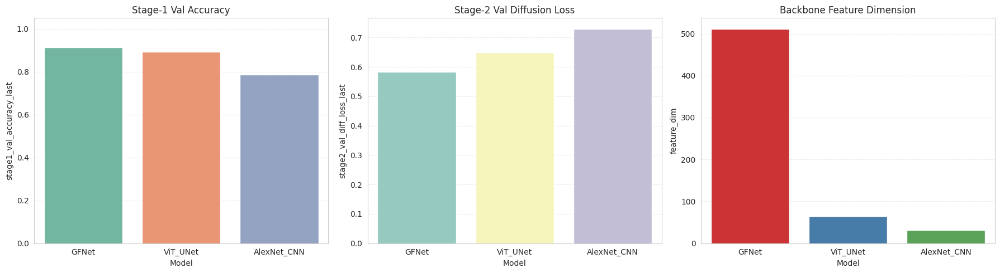

In [16]:
summary_df  = (
    pd.DataFrame([a['summary'] for a in all_artifacts])
    .sort_values('stage1_val_accuracy_last', ascending=False)
)
summary_csv = DAPM_DIR / 'dapm_full_training_summary.csv'
summary_df.to_csv(summary_csv, index=False)
print(summary_df)
print('Saved summary:', summary_csv)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=summary_df, x='model_key', y='stage1_val_accuracy_last', ax=axes[0], palette='Set2')
axes[0].set_title('Stage-1 Val Accuracy')
axes[0].set_ylim(0, 1.05)
sns.barplot(data=summary_df, x='model_key', y='stage2_val_diff_loss_last', ax=axes[1], palette='Set3')
axes[1].set_title('Stage-2 Val Diffusion Loss')
sns.barplot(data=summary_df, x='model_key', y='feature_dim', ax=axes[2], palette='Set1')
axes[2].set_title('Backbone Feature Dimension')
for ax in axes:
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.set_xlabel('Model')
fig.tight_layout()
plt.show()


## 9.2 — File & Data Integrity Checks

Asserts that all expected weight files, config JSONs, and summary rows are present
before proceeding to evaluation.

In [17]:
EXPECTED_SUFFIXES = [
    '_dapm_full_config.json',
    '_dapm_full_encoder.weights.h5',
    '_dapm_full_source_decoder.weights.h5',
    '_dapm_full_target_decoder.weights.h5',
    '_dapm_full_classifier.weights.h5',
    '_dapm_full_discriminator.weights.h5',
    '_dapm_full_diffusion.weights.h5',
]

for mk in MODEL_KEYS:
    for suf in EXPECTED_SUFFIXES:
        path = DAPM_DIR / f'{mk}{suf}'
        assert path.exists(), f'Missing artifact: {path}'

assert summary_csv.exists(), f'Missing summary csv: {summary_csv}'
assert summary_df.shape[0] == 3, f'Expected 3 summary rows, got {summary_df.shape[0]}'

for mk, dim in feature_dims.items():
    assert np.isfinite(dim), f'Non-finite feature dim for {mk}'
    assert int(dim) > 0,     f'Invalid feature dim for {mk}: {dim}'

print('Validation checks passed.')


Validation checks passed.


# 10.0 — Evaluation on Test Set

## 10.1 — Inference Helper

Defines `predict_with_dapm_classifier`, which uses the encoder → classifier path
(no diffusion) to generate predictions on any patch array.

In [18]:
def predict_with_dapm_classifier(feature_extractor, encoder, classifier, x_data, batch_size=256):
    """Run encoder → classifier inference on x_data; returns (hard_preds, softmax_probs)."""
    ds        = tf.data.Dataset.from_tensor_slices(x_data.astype(np.float32)).batch(batch_size)
    all_probs = []
    for xb in ds:
        feat       = feature_extractor(xb, training=False)
        z_mu, _, _ = encoder(feat, training=False)
        probs      = classifier(z_mu, training=False)
        all_probs.append(probs.numpy())
    all_probs = np.concatenate(all_probs, axis=0)
    return np.argmax(all_probs, axis=-1), all_probs

print('Inference utility ready.')


Inference utility ready.


## 10.2 — Compute Metrics per Model

Reloads saved weights for each backbone, runs inference on the held-out test set,
and computes OA, AA, Cohen's Kappa, and weighted F1.

In [19]:
test_results = {}

for mk in MODEL_KEYS:
    print(f"\n{'='*20} {mk} {'='*20}")

    fe = feature_extractors[mk]
    with open(DAPM_DIR / f'{mk}_dapm_full_config.json', 'r') as f:
        cfg = json.load(f)

    # Rebuild lightweight architectures and load weights
    enc = build_dapm_encoder(cfg['feature_dim'], LATENT_DIM, DECODER_HIDDEN_DIM)
    clf = build_dapm_classifier(LATENT_DIM, num_classes, CLASSIFIER_HIDDEN_DIM)
    enc.load_weights(cfg['weights']['encoder'])
    clf.load_weights(cfg['weights']['classifier'])

    preds, probs = predict_with_dapm_classifier(fe, enc, clf, x_test)

    acc   = accuracy_score(y_test, preds)
    kappa = cohen_kappa_score(y_test, preds)
    wf1   = f1_score(y_test, preds, average='weighted')
    cm    = confusion_matrix(y_test, preds, labels=np.arange(num_classes))
    cr    = classification_report(y_test, preds, labels=np.arange(num_classes), digits=4)
    aa    = np.mean(cm.diagonal() / cm.sum(axis=1).clip(min=1))

    test_results[mk] = {
        'preds': preds, 'probs': probs,
        'cm': cm, 'cr': cr,
        'acc': acc, 'aa': aa, 'kappa': kappa, 'f1': wf1,
    }

    print(f'OA={acc:.4f}  AA={aa:.4f}  \u03ba={kappa:.4f}  wF1={wf1:.4f}')
    print(cr)



==================== AlexNet_CNN ====================


OA=0.7822  AA=0.5225  κ=0.7093  wF1=0.7496
              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000      3119
           1     0.9926    1.0000    0.9963     10930
           2     0.6845    0.7611    0.7208     22500
           3     0.0000    0.0000    0.0000      1798
           4     0.7273    0.8675    0.7912     20128
           5     0.4318    0.1910    0.2648      7116
           6     0.7498    0.3920    0.5148     11317
           7     0.8319    0.9687    0.8951     47468

    accuracy                         0.7822    124376
   macro avg     0.5522    0.5225    0.5229    124376
weighted avg     0.7392    0.7822    0.7496    124376


==================== GFNet ====================


OA=0.8945  AA=0.8207  κ=0.8630  wF1=0.8933
              precision    recall  f1-score   support

           0     0.6414    0.7147    0.6761      3119
           1     0.9969    1.0000    0.9984     10930
           2     0.8779    0.8289    0.8527     22500
           3     0.5728    0.6808    0.6221      1798
           4     0.9131    0.9105    0.9118     20128
           5     0.8059    0.6577    0.7243      7116
           6     0.8478    0.8006    0.8235     11317
           7     0.9232    0.9723    0.9471     47468

    accuracy                         0.8945    124376
   macro avg     0.8224    0.8207    0.8195    124376
weighted avg     0.8942    0.8945    0.8933    124376


==================== ViT_UNet ====================


OA=0.8863  AA=0.8099  κ=0.8525  wF1=0.8850
              precision    recall  f1-score   support

           0     0.6986    0.7884    0.7408      3119
           1     0.9988    1.0000    0.9994     10930
           2     0.8567    0.8248    0.8404     22500
           3     0.5714    0.5984    0.5846      1798
           4     0.9129    0.8775    0.8949     20128
           5     0.7234    0.6190    0.6672      7116
           6     0.8202    0.8003    0.8101     11317
           7     0.9239    0.9710    0.9469     47468

    accuracy                         0.8863    124376
   macro avg     0.8132    0.8099    0.8105    124376
weighted avg     0.8849    0.8863    0.8850    124376



# 11.0 — Visualisations

## 11.1 — Confusion Matrices (Raw Counts)


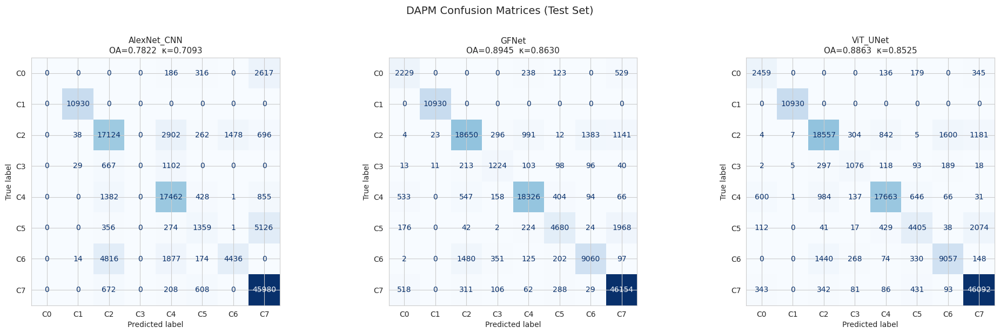

In [20]:
class_names = [f'C{i}' for i in range(num_classes)]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, mk in zip(axes, MODEL_KEYS):
    res = test_results[mk]
    ConfusionMatrixDisplay(
        confusion_matrix=res['cm'], display_labels=class_names
    ).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{mk}\nOA={res["acc"]:.4f}  \u03ba={res["kappa"]:.4f}', fontsize=11)

fig.suptitle('DAPM Confusion Matrices (Test Set)', fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(DAPM_DIR / 'confusion_matrices_raw.png', dpi=150, bbox_inches='tight')
plt.show()


## 11.2 — Confusion Matrices (Normalised Recall)

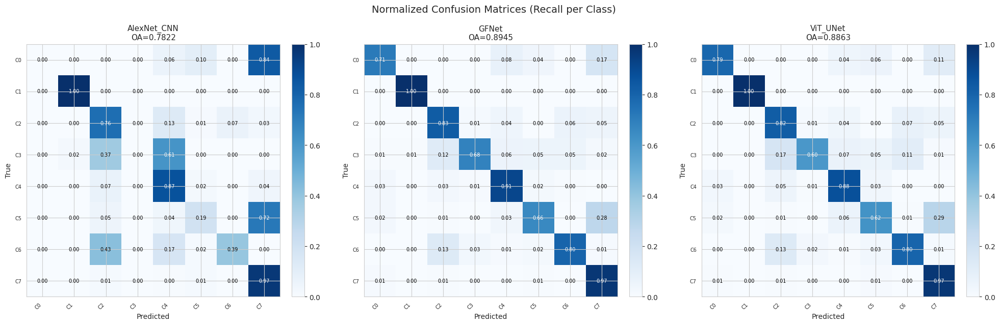

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, mk in zip(axes, MODEL_KEYS):
    cm      = test_results[mk]['cm']
    cm_norm = cm.astype(np.float64) / cm.sum(axis=1, keepdims=True)

    im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1, interpolation='nearest')
    ax.set_xticks(range(num_classes))
    ax.set_yticks(range(num_classes))
    ax.set_xticklabels(class_names, rotation=45, ha='right', fontsize=7)
    ax.set_yticklabels(class_names, fontsize=7)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'{mk}\nOA={test_results[mk]["acc"]:.4f}', fontsize=11)

    for i in range(num_classes):
        for j in range(num_classes):
            ax.text(
                j, i, f'{cm_norm[i, j]:.2f}',
                ha='center', va='center', fontsize=7,
                color='white' if cm_norm[i, j] > 0.5 else 'black',
            )

    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle('Normalized Confusion Matrices (Recall per Class)', fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(DAPM_DIR / 'confusion_matrices_normalized.png', dpi=150, bbox_inches='tight')
plt.show()


## 11.3 — Per-Class Accuracy (Recall) Bar Charts

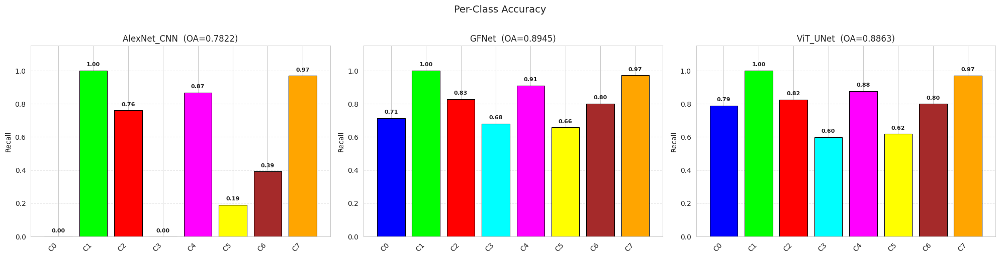

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, mk in zip(axes, MODEL_KEYS):
    cm        = test_results[mk]['cm']
    per_class = cm.diagonal() / cm.sum(axis=1).clip(min=1)
    colors    = get_class_colors(num_classes)

    bars = ax.bar(range(num_classes), per_class, color=colors, edgecolor='black', linewidth=0.8)
    for bar, v in zip(bars, per_class):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.02, f'{v:.2f}',
                ha='center', va='bottom', fontsize=8, fontweight='bold')

    ax.set_xticks(range(num_classes))
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.set_ylim(0, 1.15)
    ax.set_ylabel('Recall')
    ax.set_title(f'{mk}  (OA={test_results[mk]["acc"]:.4f})')
    ax.grid(axis='y', linestyle='--', alpha=0.4)

fig.suptitle('Per-Class Accuracy', fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(DAPM_DIR / 'per_class_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()


## 11.4 — Global Metric Comparison (OA / AA / Kappa / wF1)

      Model       OA       AA    Kappa  Weighted-F1
AlexNet_CNN 0.782233 0.522528 0.709336     0.749581
      GFNet 0.894489 0.820666 0.863043     0.893342
   ViT_UNet 0.886337 0.809933 0.852518     0.884962


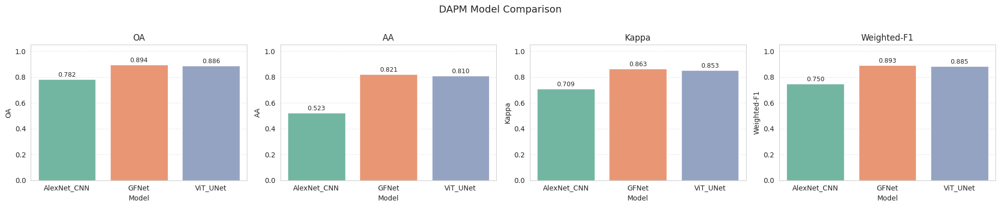

In [23]:
rows = [
    {'Model': mk, 'OA': r['acc'], 'AA': r['aa'], 'Kappa': r['kappa'], 'Weighted-F1': r['f1']}
    for mk, r in test_results.items()
]
comp_df = pd.DataFrame(rows)
print(comp_df.to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, metric in zip(axes, ['OA', 'AA', 'Kappa', 'Weighted-F1']):
    sns.barplot(data=comp_df, x='Model', y=metric, ax=ax, palette='Set2')
    ax.set_ylim(0, 1.05)
    ax.set_title(metric)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    for p in ax.patches:
        ax.text(p.get_x() + p.get_width() / 2, p.get_height() + 0.02,
                f'{p.get_height():.3f}', ha='center', fontsize=9)

fig.suptitle('DAPM Model Comparison', fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(DAPM_DIR / 'model_comparison_bars.png', dpi=150, bbox_inches='tight')
plt.show()


## 11.5 — Full-Image Classification Maps

Applies each model to every pixel in the scene to produce a dense prediction map.
Processes row-by-row to keep memory usage manageable.

Predicting full image for AlexNet_CNN ...


  row 1/1733


  row 51/1733


  row 101/1733


  row 151/1733


  row 201/1733


... (104 outputs left out)

Saved: /kaggle/working/models/ground_truth_label_map.png


Saved: /kaggle/working/models/AlexNet_CNN_classification.png


Saved: /kaggle/working/models/GFNet_classification.png


Saved: /kaggle/working/models/ViT_UNet_classification.png


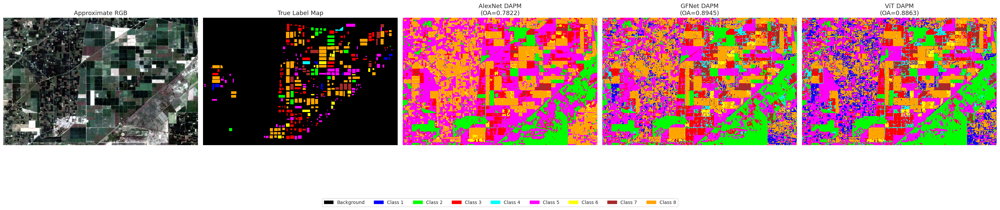

Saved overview: /kaggle/working/models/full_image_classification_maps.png


Saved Excel workbook: /kaggle/working/models/initial_classification_maps.xlsx
All visualisation outputs successfully saved to: /kaggle/working/models


In [24]:
# ── Dense Full-Scene Inference & Classification Maps ──────────────────────────
display_cmap = get_display_cmap(num_classes)
scene_rgb    = get_scene_rgb(x_img, B)
full_maps    = {}

for mk in MODEL_KEYS:
    print(f'Predicting full image for {mk} ...')
    fe  = feature_extractors[mk]
    with open(DAPM_DIR / f'{mk}_dapm_full_config.json') as f:
        cfg = json.load(f)

    enc = build_dapm_encoder(cfg['feature_dim'], LATENT_DIM, DECODER_HIDDEN_DIM)
    clf = build_dapm_classifier(LATENT_DIM, num_classes, CLASSIFIER_HIDDEN_DIM)
    enc.load_weights(cfg['weights']['encoder'])
    clf.load_weights(cfg['weights']['classifier'])

    pad      = PATCH_SIZE // 2
    x_pad    = np.pad(x_img, ((pad, pad), (pad, pad), (0, 0)), mode='edge')
    pred_map = np.zeros((H, W), dtype=np.int32)

    for r in range(H):
        # Extract all W patches along row r in one batch
        patches = np.stack(
            [x_pad[r:r + PATCH_SIZE, c:c + PATCH_SIZE, :] for c in range(W)], axis=0
        )
        feat           = fe(patches, training=False)
        z_mu, _, _     = enc(feat, training=False)
        probs          = clf(z_mu, training=False)
        pred_map[r, :] = tf.argmax(probs, axis=-1).numpy() + 1  # 1-based (1..K)
        if r % 50 == 0 or r == H - 1:
            print(f'  row {r + 1}/{H}')

    full_maps[mk] = pred_map
    print(f'  {mk} done.')

# ── Visualization Helper Functions matching baseline ──────────────────────────
def save_single_panel(image, title, save_path, cmap=None, vmin=None, vmax=None):
    """Save a single image panel as a high-DPI PNG."""
    fig, ax = plt.subplots(figsize=(8, 6))
    if cmap is None:
        ax.imshow(image)
    else:
        ax.imshow(image, cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.set_title(title, fontsize=14)
    ax.axis('off')
    fig.tight_layout()
    fig.savefig(save_path, dpi=220, bbox_inches='tight')
    plt.close(fig)
    print('Saved:', save_path)

def save_combined_overview(rgb_image, y_true, pred_maps, test_res, num_classes, save_path):
    """Save a clean five-panel side-by-side overview with non-overlapping horizontal legend."""
    cmap = get_display_cmap(num_classes)
    panels = [
        ("Approximate RGB",                rgb_image,                  "rgb"),
        ("True Label Map",                 y_true,                     "label"),
        (f"AlexNet DAPM\n(OA={test_res['AlexNet_CNN']['acc']:.4f})", pred_maps.get("AlexNet_CNN"), "label"),
        (f"GFNet DAPM\n(OA={test_res['GFNet']['acc']:.4f})",       pred_maps.get("GFNet"),       "label"),
        (f"ViT DAPM\n(OA={test_res['ViT_UNet']['acc']:.4f})",     pred_maps.get("ViT_UNet"),    "label"),
    ]

    fig, axes = plt.subplots(1, len(panels), figsize=(30, 7), sharex=True, sharey=True)
    for ax, (title, img, kind) in zip(axes, panels):
        ax.set_title(title, fontsize=13)
        if kind == "rgb":
            ax.imshow(img)
        elif img is None:
            ax.imshow(np.zeros_like(y_true), cmap=cmap, vmin=0, vmax=num_classes, interpolation='nearest')
            ax.text(0.5, 0.5, "Unavailable", ha="center", va="center", fontsize=10, transform=ax.transAxes)
        else:
            ax.imshow(img, cmap=cmap, vmin=0, vmax=num_classes, interpolation='nearest')
        ax.axis("off")

    handles = [plt.Rectangle((0, 0), 1, 1, color=BACKGROUND_COLOR, label="Background")]
    class_colors = get_class_colors(num_classes)
    for i in range(num_classes):
        handles.append(plt.Rectangle((0, 0), 1, 1, color=class_colors[i], label=f"Class {i+1}"))
    fig.legend(handles=handles, loc="lower center", ncol=min(num_classes + 1, 9),
               bbox_to_anchor=(0.5, -0.02), frameon=True)
    fig.tight_layout(rect=[0, 0.05, 1, 1])
    fig.savefig(save_path, dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print('Saved overview:', save_path)

def save_images_to_excel(excel_path, image_paths, sheet_name="Initial_Classification_Maps"):
    """Embed PNG images into an Excel workbook at fixed anchor positions."""
    try:
        from openpyxl import Workbook, load_workbook
        from openpyxl.drawing.image import Image as XLImage
    except ImportError:
        print("openpyxl not available; skipping Excel image embedding.")
        return

    if excel_path.exists():
        wb = load_workbook(excel_path)
        if sheet_name in wb.sheetnames:
            del wb[sheet_name]
        ws = wb.create_sheet(title=sheet_name)
    else:
        wb = Workbook()
        ws = wb.active
        ws.title = sheet_name

    anchors = ["A1", "J1", "A25", "J25", "A49", "J49"]
    for path, anchor in zip(image_paths, anchors):
        if Path(path).exists():
            img = XLImage(str(path))
            img.anchor = anchor
            ws.add_image(img)

    wb.save(excel_path)
    print("Saved Excel workbook:", excel_path)

# ── Save Individual PNGs and Combined Overview ─────────────────────────────────
rgb_png      = DAPM_DIR / "scene_rgb.png"
gt_png       = DAPM_DIR / "ground_truth_label_map.png"
alex_png     = DAPM_DIR / "AlexNet_CNN_classification.png"
gfnet_png    = DAPM_DIR / "GFNet_classification.png"
vit_png      = DAPM_DIR / "ViT_UNet_classification.png"
overview_png = DAPM_DIR / "full_image_classification_maps.png"
combined_png = DAPM_DIR / "combined_initial_classification_overview.png"
vis_excel    = DAPM_DIR / "initial_classification_maps.xlsx"

save_single_panel(scene_rgb, "Approximate RGB", rgb_png)
save_single_panel(y_img, "Ground Truth Label Map", gt_png, cmap=display_cmap, vmin=0, vmax=num_classes)

if full_maps.get("AlexNet_CNN") is not None:
    save_single_panel(full_maps["AlexNet_CNN"], "AlexNet DAPM Classification",
                      alex_png, cmap=display_cmap, vmin=0, vmax=num_classes)

if full_maps.get("GFNet") is not None:
    save_single_panel(full_maps["GFNet"], "GFNet DAPM Classification",
                      gfnet_png, cmap=display_cmap, vmin=0, vmax=num_classes)

if full_maps.get("ViT_UNet") is not None:
    save_single_panel(full_maps["ViT_UNet"], "ViT DAPM Classification",
                      vit_png, cmap=display_cmap, vmin=0, vmax=num_classes)

save_combined_overview(
    rgb_image=scene_rgb, y_true=y_img, pred_maps=full_maps,
    test_res=test_results, num_classes=num_classes, save_path=overview_png,
)
# Save copy to combined_initial_classification_overview.png for baseline symmetry
import shutil
shutil.copy2(overview_png, combined_png)

# Save into Excel
image_paths_for_excel = [rgb_png, gt_png, alex_png, gfnet_png, vit_png, overview_png]
if "save_images_to_excel" in globals():
    try:
        save_images_to_excel(vis_excel, image_paths_for_excel)
    except Exception as exc:
        print(f"Warning: save_images_to_excel failed: {exc}")

print("All visualisation outputs successfully saved to:", DAPM_DIR)
